# Parte 3 — Aprendizaje no supervisado, interpretación de negocio y conclusiones

**Caso B — Predicción de precios de viviendas (Ames Iowa Housing).**

Esta parte responde dos preguntas:

1. ¿Existen **segmentos de viviendas** con características parecidas entre sí (IE7)?
2. ¿Qué dicen esos segmentos sobre **dónde el modelo supervisado funciona mejor o peor** y qué se recomienda hacer en consecuencia (IE8)?

Reglas de trabajo, heredadas del README (secciones 4 y 6.3):

- Entrada: `data/processed/features_full.csv` (Parte 1), que **no contiene el precio**. El precio solo se usa **después** de formar los segmentos, para describirlos. Así los segmentos no se construyen "a la medida" del precio.
- `random_state=42` en todo lo aleatorio.
- El conjunto de prueba se usa solo para medir el error del modelo ya elegido en cada segmento (sección 6). No se usó para decidir nada del clustering ni del modelo.
- **CRISP-DM:** esta parte cubre modelado no supervisado (fase 4), evaluación de segmentos y del modelo por segmento (fase 5) y comunicación de recomendaciones (fase 6).

In [1]:
from pathlib import Path
import sys
import warnings

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from IPython.display import display
from sklearn.cluster import AgglomerativeClustering, KMeans
from sklearn.decomposition import PCA
from sklearn.metrics import adjusted_rand_score, davies_bouldin_score, silhouette_score

warnings.filterwarnings("ignore", category=FutureWarning)

directorio_actual = Path.cwd()
if (directorio_actual / "src").is_dir():
    ROOT = directorio_actual
elif (directorio_actual.parent / "src").is_dir():
    ROOT = directorio_actual.parent
else:
    raise FileNotFoundError("Abre el notebook desde la raíz del proyecto o desde su carpeta notebooks.")

if str(ROOT) not in sys.path:
    sys.path.insert(0, str(ROOT))

from src.clustering import (
    SEMILLA, cargar_features_clustering, cargar_originales_alineados, error_por_segmento,
    evaluar_k, nombrar_segmentos, perfilar_segmentos,
)
from src.data_prep import cargar_y_separar
from src.predict import cargar_modelo, predecir
from src.utils import DATA_PROCESSED, MODELS, load_data

IMAGES = ROOT / "images"
IMAGES.mkdir(exist_ok=True)

pd.set_option("display.width", 200)
pd.set_option("display.max_columns", 30)
plt.rcParams.update({"figure.dpi": 110, "axes.spines.top": False, "axes.spines.right": False})
K_FINAL = 5   # valor elegido en la sección 3; se cambia solo si cambia la decisión

## 1. Datos de entrada y variables usadas

Se carga `features_full.csv` con `load_data()`: las 2.930 viviendas ya transformadas en la Parte 1 (imputación, estandarización y codificación one-hot, ajustadas con entrenamiento). `referencia_filas.csv` permite volver a los datos originales para describir los segmentos con variables legibles.

**Decisión: se excluyen las columnas de `Sale Type` y `Sale Condition`.** Describen cómo se cerró la venta (contrato, venta parcial, ejecución hipotecaria…) y no la vivienda. En la Parte 2 ya se excluyeron del modelo por ser información posterior a la venta (README, sección 12.1). Aquí se aplica el mismo criterio para que los segmentos agrupen **viviendas** y no **tipos de transacción**. *Alternativa descartada:* dejarlas; habría mezclado en un mismo grupo viviendas distintas solo porque se vendieron de forma parecida.

Variables **no** usadas: `SalePrice` (no está en `features_full.csv`), `Order` y `PID` (identificadores, excluidos desde la Parte 1).

In [2]:
X, ref, columnas_excluidas = cargar_features_clustering()
originales = cargar_originales_alineados(ref)

assert len(X) == len(originales) == 2930
assert X.isna().sum().sum() == 0

pd.Series({
    "viviendas": X.shape[0],
    "columnas_en_features_full": X.shape[1] + len(columnas_excluidas),
    "columnas_excluidas_(Sale Type / Sale Condition)": len(columnas_excluidas),
    "columnas_usadas_para_clustering": X.shape[1],
})

viviendas                                          2930
columnas_en_features_full                           339
columnas_excluidas_(Sale Type / Sale Condition)      16
columnas_usadas_para_clustering                     323
dtype: int64

## 2. Reducción de dimensionalidad con PCA (C16)

**Por qué PCA antes de agrupar.** Las 323 columnas son en su mayoría variables one-hot (categorías) estandarizadas. En un espacio de tantas dimensiones casi todas las distancias se parecen y K-Means (que usa distancia euclidiana) funciona peor; además, las categorías raras añaden ruido. PCA resume la información en pocas componentes ortogonales y elimina parte de ese ruido.

**Criterio para elegir cuántas componentes:** conservar al menos el **80 % de la varianza**. Es un compromiso: con menos componentes se pierde información de la vivienda; con más, el ruido vuelve a pesar.

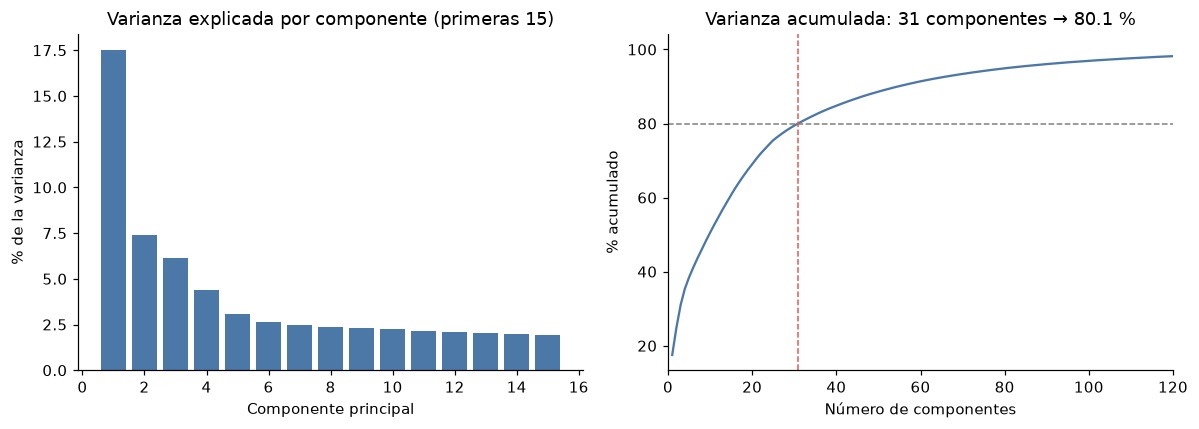

componentes_para_80%    31.0000
varianza_acumulada       0.8007
varianza_PC1             0.1750
varianza_PC2             0.0738
varianza_PC1+PC2         0.2488
dtype: float64

In [3]:
pca_completo = PCA(random_state=SEMILLA).fit(X)
varianza = pca_completo.explained_variance_ratio_
acumulada = np.cumsum(varianza)
N_COMP = int(np.searchsorted(acumulada, 0.80) + 1)

fig, ax = plt.subplots(1, 2, figsize=(11, 4))
ax[0].bar(range(1, 16), varianza[:15] * 100, color="#4C78A8")
ax[0].set_title("Varianza explicada por componente (primeras 15)")
ax[0].set_xlabel("Componente principal")
ax[0].set_ylabel("% de la varianza")

ax[1].plot(range(1, len(acumulada) + 1), acumulada * 100, color="#4C78A8")
ax[1].axhline(80, color="gray", ls="--", lw=1)
ax[1].axvline(N_COMP, color="#E45756", ls="--", lw=1)
ax[1].set_title(f"Varianza acumulada: {N_COMP} componentes → {acumulada[N_COMP-1]*100:.1f} %")
ax[1].set_xlabel("Número de componentes")
ax[1].set_ylabel("% acumulado")
ax[1].set_xlim(0, 120)
plt.tight_layout()
plt.savefig(IMAGES / "clustering_pca_varianza.png", bbox_inches="tight")
plt.show()

pd.Series({
    "componentes_para_80%": N_COMP,
    "varianza_acumulada": round(float(acumulada[N_COMP - 1]), 4),
    "varianza_PC1": round(float(varianza[0]), 4),
    "varianza_PC2": round(float(varianza[1]), 4),
    "varianza_PC1+PC2": round(float(acumulada[1]), 4),
})

**Lectura.** Se necesitan **31 componentes** para llegar al 80 % de la varianza (80,1 %). La información está repartida: la primera componente explica 17,5 % y las dos primeras juntas 24,9 %. Consecuencias:

- El clustering se hace sobre las **31 componentes**, no sobre 2.
- Los gráficos en 2 dimensiones (sección 5) son una **vista parcial**: solo muestran el 24,9 % de la varianza, así que dos segmentos pueden verse superpuestos aunque en el espacio completo estén separados.

In [4]:
pca = PCA(n_components=N_COMP, random_state=SEMILLA)
Z = pca.fit_transform(X)
Z.shape

(2930, 31)

## 3. K-Means: selección de k (C17)

K-Means divide las viviendas en *k* grupos minimizando la distancia de cada vivienda al centro de su grupo. Se eligió porque es el método estándar de segmentación, escala bien, y sus segmentos se resumen fácilmente con "una vivienda típica" por grupo (útil para el negocio).

Se evalúa *k* de 2 a 10 con cuatro criterios (el plan exige al menos dos: codo y silhouette):

| Criterio | Qué mide | Cómo se lee |
|---|---|---|
| Inercia (codo) | Dispersión dentro de los grupos | Se busca el punto donde dejar de ganar mucho al subir *k* |
| Silhouette | Qué tan separado está cada punto de otros grupos (−1 a 1) | Más alto es mejor |
| Davies-Bouldin | Solapamiento entre grupos | Más bajo es mejor |
| Estabilidad (ARI bootstrap) | Si el agrupamiento se repite al re-entrenar con muestras remuestreadas | Más cerca de 1 es mejor |

,inercia,silhouette,davies_bouldin,estabilidad_ARI,estabilidad_sd,n_min_cluster
k,,,,,,
2,99653.798,0.169,2.123,0.989,0.007,1295
3,93673.985,0.151,2.244,0.920,0.137,678
4,89167.429,0.113,2.638,0.844,0.132,572
5,85483.901,0.118,2.405,0.867,0.084,118
6,82334.329,0.110,2.279,0.781,0.155,119
7,79563.341,0.111,2.086,0.789,0.113,25
8,77263.072,0.104,2.202,0.715,0.130,25
9,74847.945,0.107,2.073,0.661,0.103,25
10,73636.341,0.095,2.263,0.678,0.089,25


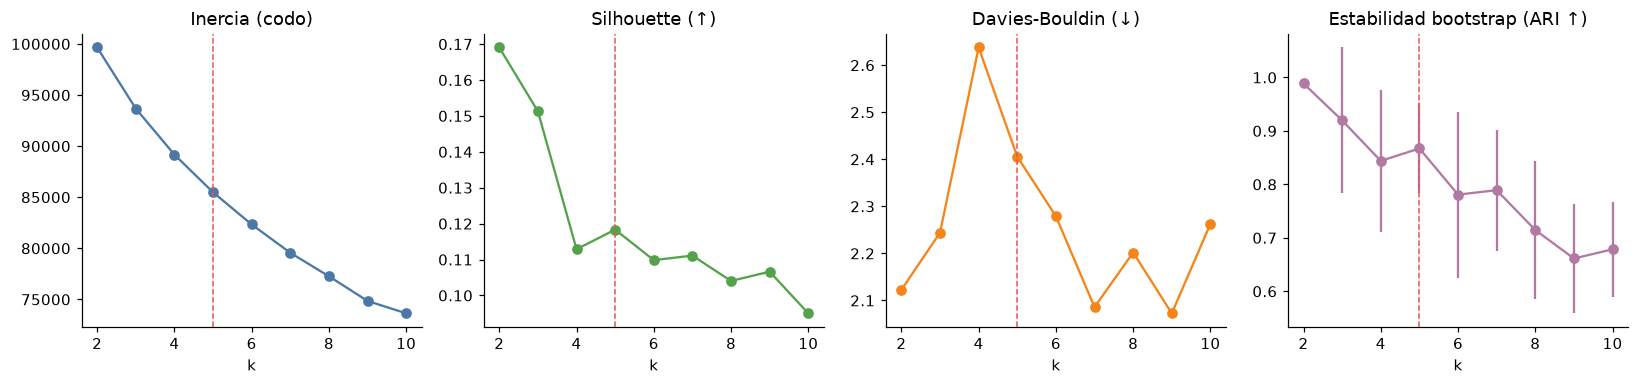

In [5]:
tabla_k = evaluar_k(Z, range(2, 11), n_boot=20)
display(tabla_k.round(3).set_index("k"))

fig, ax = plt.subplots(1, 4, figsize=(15, 3.6))
ks = tabla_k["k"]
ax[0].plot(ks, tabla_k["inercia"], "o-", color="#4C78A8"); ax[0].set_title("Inercia (codo)")
ax[1].plot(ks, tabla_k["silhouette"], "o-", color="#54A24B"); ax[1].set_title("Silhouette (↑)")
ax[2].plot(ks, tabla_k["davies_bouldin"], "o-", color="#F58518"); ax[2].set_title("Davies-Bouldin (↓)")
ax[3].errorbar(ks, tabla_k["estabilidad_ARI"], yerr=tabla_k["estabilidad_sd"], fmt="o-", color="#B279A2")
ax[3].set_title("Estabilidad bootstrap (ARI ↑)")
for a in ax:
    a.set_xlabel("k"); a.axvline(K_FINAL, color="#E45756", ls="--", lw=1)
plt.tight_layout()
plt.savefig(IMAGES / "clustering_k.png", bbox_inches="tight")
plt.show()

**Decisión: k = 5.** Argumento, con los números de la tabla:

1. **El codo no es nítido.** La inercia baja de forma continua; no hay un quiebre claro. Por eso no basta un solo criterio.
2. **Silhouette y estabilidad favorecen k bajos** (k = 2: silhouette 0,169 y ARI 0,989). Pero k = 2 solo separa "viviendas pequeñas y antiguas" de "grandes y nuevas": es demasiado grueso para orientar decisiones. *Alternativa descartada.*
3. **Entre k = 3 y k = 10, k = 5 es un máximo local:** el silhouette sube de 0,113 (k = 4) a 0,118 (k = 5) y Davies-Bouldin mejora de 2,64 a 2,41. Además la estabilidad (0,867) es mayor que en k = 4 y k ≥ 6.
4. **k = 5 revela un segmento que k = 3 y k = 4 ocultan:** un grupo pequeño de dúplex y viviendas multifamiliares (118 viviendas, 4 % del total) con un perfil claramente distinto. Con k ≥ 7 aparecen grupos de solo 25 viviendas, demasiado pequeños para interpretar.
5. **Costo de esta elección:** k = 3 tiene mejor silhouette (0,151) y es más estable. Se acepta perder algo de cohesión matemática a cambio de segmentos más útiles para el negocio.

**Advertencia honesta:** todos los silhouette son bajos (≤ 0,17). Los datos **no forman grupos naturales bien separados**: los segmentos son una *partición útil* de un continuo de viviendas, no "tipos" que existan por separado. Esto se retoma en las limitaciones.

In [6]:
kmeans = KMeans(n_clusters=K_FINAL, n_init=20, random_state=SEMILLA).fit(Z)
etiquetas_km = kmeans.labels_
pd.Series(np.bincount(etiquetas_km), name="viviendas por cluster").rename_axis("cluster_km")

cluster_km
0    118
1    866
2    692
3    580
4    674
Name: viviendas por cluster, dtype: int64

## 4. Segundo enfoque para contraste: clustering jerárquico de Ward (C18)

Para comprobar que los segmentos no son un artefacto de K-Means se repite el agrupamiento con un método distinto: **clustering jerárquico aglomerativo con enlace de Ward**, que va fusionando viviendas de abajo hacia arriba minimizando el aumento de varianza. Se compara con K-Means usando el mismo *k*, las mismas 31 componentes y las mismas métricas.

*DBSCAN no se probó.* Se descartó por diseño: agrupa por densidad con un solo radio, lo que funciona mal con densidades distintas entre grupos (hay muchas más viviendas de precio medio que dúplex) y en 31 dimensiones. No hay resultados que respalden esta decisión; es un criterio a priori.

In [7]:
ward = AgglomerativeClustering(n_clusters=K_FINAL, linkage="ward").fit(Z)
etiquetas_ward = ward.labels_

comparacion = pd.DataFrame({
    "silhouette": [silhouette_score(Z, etiquetas_km), silhouette_score(Z, etiquetas_ward)],
    "davies_bouldin": [davies_bouldin_score(Z, etiquetas_km), davies_bouldin_score(Z, etiquetas_ward)],
    "tamaños_de_grupo": [sorted(np.bincount(etiquetas_km), reverse=True), sorted(np.bincount(etiquetas_ward), reverse=True)],
}, index=["K-Means", "Ward"])
display(comparacion.round(3))

ari = adjusted_rand_score(etiquetas_km, etiquetas_ward)
print(f"ARI entre K-Means y Ward: {ari:.3f}")

display(pd.crosstab(
    pd.Series(etiquetas_km, name="cluster K-Means"),
    pd.Series(etiquetas_ward, name="cluster Ward"),
))

,silhouette,davies_bouldin,tamaños_de_grupo
K-Means,0.118,2.405,"[866, 692, 674, 580, 118]"
Ward,0.091,2.516,"[917, 665, 632, 599, 117]"


ARI entre K-Means y Ward: 0.595


cluster Ward,0,1,2,3,4
cluster K-Means,,,,,
0,1,1,1,1,114
1,36,68,18,741,3
2,1,546,69,76,0
3,505,0,0,75,0
4,122,17,511,24,0


**Comparación y elección.**

- **Coincidencia moderada (ARI = 0,595).** Ambos métodos encuentran una estructura parecida —en particular, los dos aíslan un grupo de ~117–118 viviendas (los dúplex)— pero no idéntica. Los segmentos son razonablemente robustos al método, sin ser exactos.
- **K-Means cohesiona mejor:** silhouette 0,118 frente a 0,091 y Davies-Bouldin 2,41 frente a 2,52.
- **Se elige K-Means como enfoque final.** Tiene mejores métricas, se explica con "centros" y permite asignar viviendas nuevas a un segmento con `predict`, algo que Ward no ofrece directamente.

## 5. Perfilamiento de segmentos y patrones de negocio (C19)

Ahora sí se usa la información de las viviendas originales y el precio para **describir** cada grupo. Los nombres se asignan con reglas sobre características **observables de la vivienda** (tipo de edificación, pisos, año de construcción), no por el número del cluster —que es arbitrario— y **no por barrio**, para no estigmatizar zonas (README, sección 7.1).

In [8]:
datos = originales.copy()
datos["cluster"] = etiquetas_km
nombres = nombrar_segmentos(datos)
datos["segmento"] = datos["cluster"].map(nombres)

perfil = perfilar_segmentos(datos)
display(perfil.round(2).T)

# Guardar la asignación (contrato de interfaces: data/processed/clusters.csv)
clusters = pd.DataFrame({
    "indice_original": ref.to_numpy(),
    "cluster": datos["cluster"].to_numpy(),
    "segmento": datos["segmento"].to_numpy(),
})
clusters.to_csv(DATA_PROCESSED / "clusters.csv", index=False)
print("clusters.csv:", clusters.shape)

segmento,S1 Dúplex y multifamiliares,S2 Antiguas y compactas,"S3 Un piso de tamaño medio, construcción de los años 60",S4 Un piso de construcción reciente y mayor calidad,"S5 Dos pisos amplias, construcción reciente"
n,118.00,692.00,866.00,580.00,674.00
precio_mediano,129250.00,117800.00,143350.00,230174.00,212000.00
precio_q1,106537.50,96500.00,129050.00,194650.00,180000.00
precio_q3,145675.00,138000.00,160000.00,290000.00,265000.00
superficie_habitable_pies2,1731.00,1246.50,1126.50,1558.50,1887.50
calidad_general,5.00,5.00,5.00,7.00,7.00
anio_construccion,1958.00,1933.00,1965.00,2005.00,1999.00
superficie_lote_pies2,9000.00,7447.50,9629.00,10000.00,10372.00
sotano,958.50,742.00,1040.00,1524.50,917.00
autos_garaje,2.00,1.00,2.00,2.00,2.00


clusters.csv: (2930, 3)


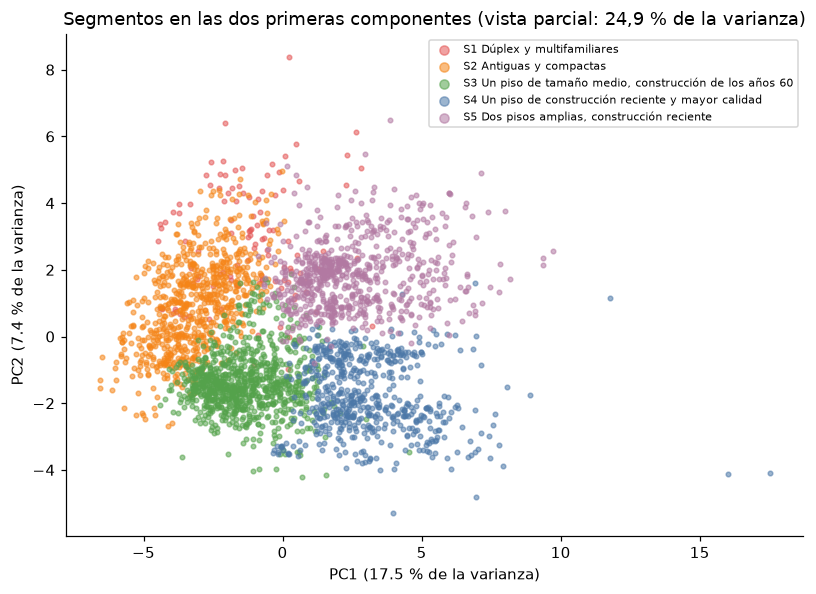

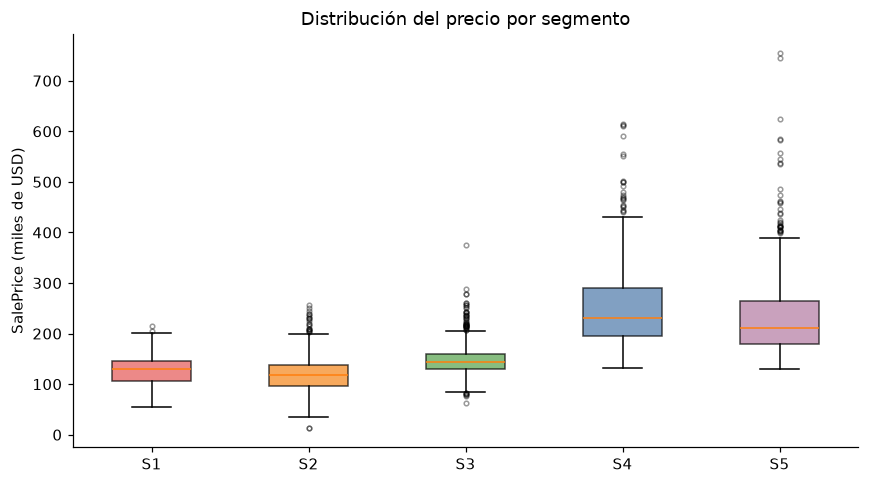

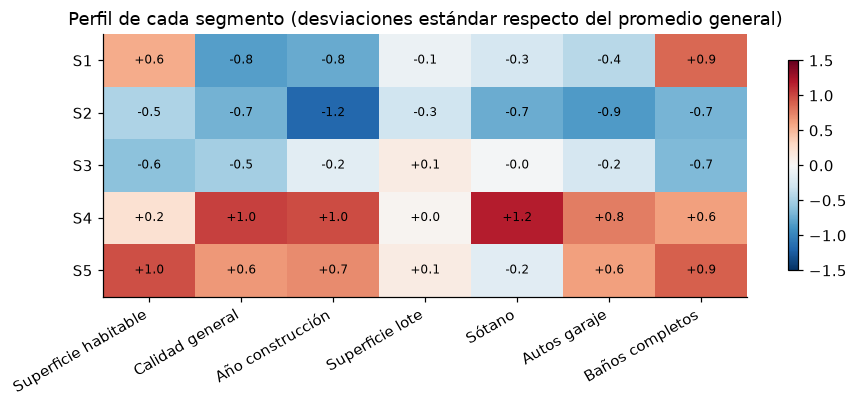

In [9]:
orden = sorted(datos["segmento"].unique())
etiq_corta = {s: s.split(" ")[0] for s in orden}
colores = dict(zip(orden, ["#E45756", "#F58518", "#54A24B", "#4C78A8", "#B279A2"]))

# Figura 1: mapa PCA 2D
fig, ax = plt.subplots(figsize=(7.5, 5.5))
for s in orden:
    m = (datos["segmento"] == s).to_numpy()
    ax.scatter(Z[m, 0], Z[m, 1], s=9, alpha=0.55, color=colores[s], label=s)
ax.set_xlabel(f"PC1 ({varianza[0]*100:.1f} % de la varianza)")
ax.set_ylabel(f"PC2 ({varianza[1]*100:.1f} % de la varianza)")
ax.set_title("Segmentos en las dos primeras componentes (vista parcial: 24,9 % de la varianza)")
ax.legend(fontsize=7, markerscale=2, loc="best")
plt.tight_layout()
plt.savefig(IMAGES / "segmentos_pca.png", bbox_inches="tight")
plt.show()

# Figura 2: distribución del precio por segmento
fig, ax = plt.subplots(figsize=(8, 4.5))
datos_box = [datos.loc[datos["segmento"] == s, "SalePrice"] / 1000 for s in orden]
bp = ax.boxplot(datos_box, tick_labels=[etiq_corta[s] for s in orden], patch_artist=True, showfliers=True,
                flierprops={"markersize": 3, "alpha": 0.4})
for patch, s in zip(bp["boxes"], orden):
    patch.set_facecolor(colores[s]); patch.set_alpha(0.7)
ax.set_ylabel("SalePrice (miles de USD)")
ax.set_title("Distribución del precio por segmento")
plt.tight_layout()
plt.savefig(IMAGES / "segmentos_precio.png", bbox_inches="tight")
plt.show()

# Figura 3: perfil estandarizado (mediana de cada variable, en desviaciones respecto del conjunto)
variables = {"Gr Liv Area": "Superficie habitable", "Overall Qual": "Calidad general", "Year Built": "Año construcción",
             "Lot Area": "Superficie lote", "Total Bsmt SF": "Sótano", "Garage Cars": "Autos garaje", "Full Bath": "Baños completos"}
medias = datos.groupby("segmento")[list(variables)].mean()
z = (medias - datos[list(variables)].mean()) / datos[list(variables)].std()
fig, ax = plt.subplots(figsize=(8.5, 3.8))
im = ax.imshow(z.loc[orden].to_numpy(), cmap="RdBu_r", vmin=-1.5, vmax=1.5, aspect="auto")
ax.set_xticks(range(len(variables))); ax.set_xticklabels(list(variables.values()), rotation=30, ha="right")
ax.set_yticks(range(len(orden))); ax.set_yticklabels([etiq_corta[s] for s in orden])
for i in range(len(orden)):
    for j in range(len(variables)):
        ax.text(j, i, f"{z.loc[orden[i]].iloc[j]:+.1f}", ha="center", va="center", fontsize=8)
ax.set_title("Perfil de cada segmento (desviaciones estándar respecto del promedio general)")
plt.colorbar(im, ax=ax, shrink=0.8)
plt.tight_layout()
plt.savefig(IMAGES / "segmentos_perfil.png", bbox_inches="tight")
plt.show()

In [10]:
# Cruce con el precio usando los cuartiles del ENTRENAMIENTO (mismos rangos del README, sección 12.5)
_, _, y_train_raw, _ = cargar_y_separar()
q1_entrenamiento = y_train_raw.quantile(0.25)
mediana_entrenamiento = y_train_raw.median()

cruce = pd.DataFrame({
    "% del segmento con precio ≤ Q1 (129.000)": datos.assign(bajo=datos["SalePrice"] <= q1_entrenamiento).groupby("segmento")["bajo"].mean(),
    "variación del precio dentro del segmento (desv./media)": datos.groupby("segmento")["SalePrice"].std() / datos.groupby("segmento")["SalePrice"].mean(),
})
display(cruce.round(2))
print(f"Q1 del entrenamiento: {q1_entrenamiento:,.0f} USD | mediana del entrenamiento: {mediana_entrenamiento:,.0f} USD")

,% del segmento con precio ≤ Q1 (129.000),variación del precio dentro del segmento (desv./media)
segmento,,
S1 Dúplex y multifamiliares,0.50,0.24
S2 Antiguas y compactas,0.65,0.30
"S3 Un piso de tamaño medio, construcción de los años 60",0.25,0.20
S4 Un piso de construcción reciente y mayor calidad,0.00,0.32
"S5 Dos pisos amplias, construcción reciente",0.00,0.34


Q1 del entrenamiento: 129,000 USD | mediana del entrenamiento: 160,000 USD


### Descripción de los segmentos

Medianas calculadas sobre las 2.930 viviendas. Superficies en pies cuadrados, precios en USD.

| Segmento | n (%) | Precio mediano (rango intercuartil) | Qué lo caracteriza | Relevancia para el negocio |
|---|---|---|---|---|
| **S1 Dúplex y multifamiliares** | 118 (4 %) | 129.250 (106.538–145.675) | 94 % son dúplex o 2fmCon; superficie grande (1.731) para su precio; 2 baños | Producto distinto a una casa unifamiliar; muy pocos casos para que el modelo aprenda su precio. |
| **S2 Antiguas y compactas** | 692 (24 %) | 117.800 (96.500–138.000) | Año 1933; superficie 1.247; 1 auto; 50 % en zona residencial de mayor densidad (RM); lotes pequeños | Concentra el rango de precios bajos: 65 % tiene precio ≤ 129.000 (Q1), el rango donde la Parte 2 midió la menor cobertura (63,3 %, README, sección 12.5). |
| **S3 Un piso de tamaño medio, años 60** | 866 (30 %) | 143.350 (129.050–160.000) | 78 % de un piso; año 1965; superficie 1.127; calidad 5 | Vivienda "típica" y el segmento más grande; precios homogéneos alrededor de la mediana. |
| **S4 Un piso reciente y de mayor calidad** | 580 (20 %) | 230.174 (194.650–290.000) | 95 % de un piso; año 2005; calidad 7; sótano grande (1.525); 27 % townhouse | Alto valor por operación: ninguna vivienda con precio ≤ 129.000 y mediana de 230.174. |
| **S5 Dos pisos amplias, recientes** | 674 (23 %) | 212.000 (180.000–265.000) | 90 % de dos pisos; año 1999; superficie 1.888; calidad 7; 2 baños completos | Familias grandes; precios altos pero con más dispersión interna (desv./media 0,34). |

**Patrones de negocio que dejan ver los segmentos:**

1. **El precio se organiza por dos ejes combinados: antigüedad/calidad y tamaño/tipo de edificación.** Las viviendas recientes y de calidad 7 (S4, S5) valen 1,5 a 2 veces las de calidad 5 (S1–S3), incluso con superficies similares (S4: 1.559 frente a S1: 1.731). Esto es una asociación, no una causa.
2. **Las viviendas antiguas y compactas (S2) son el grupo más ligado a los precios bajos:** 65 % de ellas está en el cuartil inferior de precios (≤ 129.000 USD), frente a 25 % en S3 y 0 % en S4.
3. **Dentro de S4 y S5 hay mucha más dispersión de precios** (desv./media 0,32 y 0,34) que en S3 (0,20): un mismo segmento admite un rango amplio de valores, lo que hace más difícil estimar con un solo número.
4. **Barrios:** S4 y S5 reúnen viviendas de barrios como NridgHt, CollgCr, Somerst y Gilbert; S2 se concentra en OldTown, BrkSide e IDOTRR. La ubicación influyó en cómo se formaron los grupos (`Neighborhood` está entre las variables), pero esto describe **propiedades**, no a sus habitantes.

## 6. Integración con el modelo supervisado (C20)

El modelo ganador de la Parte 2 (Boosting ajustado, `models/best_model.joblib`) se evalúa **por segmento**, usando solo las 586 viviendas de prueba. Las viviendas de entrenamiento no se usan aquí porque el modelo ya las vio y su error sería artificialmente bajo.

Además del MAE y la cobertura ±10 % de los KPIs (README, sección 4), se reporta un **intervalo de confianza de Wilson al 95 %** para la cobertura, porque con pocas viviendas por segmento la cifra puntual es poco precisa.

In [11]:
modelo = cargar_modelo()

_, X_test_crudo, _, y_test_crudo = cargar_y_separar()
posicion = pd.Series(np.arange(len(ref)), index=ref.to_numpy())
prueba = datos.iloc[posicion.loc[X_test_crudo.index].to_numpy()].copy()
assert len(prueba) == 586 and np.allclose(prueba["SalePrice"].to_numpy(), y_test_crudo.to_numpy())

prueba["precio_predicho"] = predecir(prueba, modelo).to_numpy()

por_segmento = error_por_segmento(prueba)
global_ = error_por_segmento(prueba.assign(segmento="TOTAL (586 viviendas)"))

# Mejora del MAE frente a la referencia de la mediana del entrenamiento, por segmento
prueba["ae_modelo"] = (prueba["precio_predicho"] - prueba["SalePrice"]).abs()
prueba["ae_referencia"] = (prueba["SalePrice"] - mediana_entrenamiento).abs()
mae_ref = prueba.groupby("segmento")["ae_referencia"].mean()
por_segmento["MAE_referencia_USD"] = mae_ref
por_segmento["mejora_MAE_vs_referencia"] = 1 - por_segmento["MAE_USD"] / mae_ref
por_segmento["cumple_cobertura_70_puntual"] = por_segmento["cobertura_10"] >= 0.70
por_segmento["IC95_incluye_70"] = (por_segmento["cobertura_IC95_inf"] < 0.70) & (por_segmento["cobertura_IC95_sup"] >= 0.70)

resultado = pd.concat([por_segmento, global_])
display(resultado.round(3))

# Comprobación cruzada con la Parte 2: el total debe coincidir con results_supervised.csv
res_p2 = pd.read_csv(MODELS / "results_supervised.csv")
fila = res_p2[res_p2["seleccionado"]].iloc[0]
assert abs(global_["MAE_USD"].iloc[0] - fila["MAE_prueba"]) < 1, "El MAE total no coincide con la Parte 2"
assert abs(global_["cobertura_10"].iloc[0] - fila["Cobertura10_prueba"]) < 1e-9
print(f"OK: total coincide con la Parte 2 → MAE {fila['MAE_prueba']:,.0f} USD, cobertura {fila['Cobertura10_prueba']:.1%}")

resultado.to_csv(MODELS / "results_segments.csv")

,n_prueba,MAE_USD,error_relativo_mediano,cobertura_10,cobertura_IC95_inf,cobertura_IC95_sup,MAE_referencia_USD,mejora_MAE_vs_referencia,cumple_cobertura_70_puntual,IC95_incluye_70
segmento,,,,,,,,,,
S1 Dúplex y multifamiliares,26,10013.216,0.054,0.731,0.539,0.863,33632.500,0.702,True,True
S2 Antiguas y compactas,135,10016.933,0.061,0.696,0.614,0.768,45949.548,0.782,False,True
"S3 Un piso de tamaño medio, construcción de los años 60",151,9296.817,0.050,0.768,0.695,0.828,24096.894,0.614,True,True
S4 Un piso de construcción reciente y mayor calidad,132,26176.694,0.061,0.712,0.630,0.782,111241.621,0.765,True,True
"S5 Dos pisos amplias, construcción reciente",142,17768.227,0.048,0.810,0.737,0.866,84570.197,0.790,True,False
TOTAL (586 viviendas),586,15349.592,0.055,0.747,0.711,0.781,NaN,NaN,NaN,NaN


OK: total coincide con la Parte 2 → MAE 15,350 USD, cobertura 74.7%


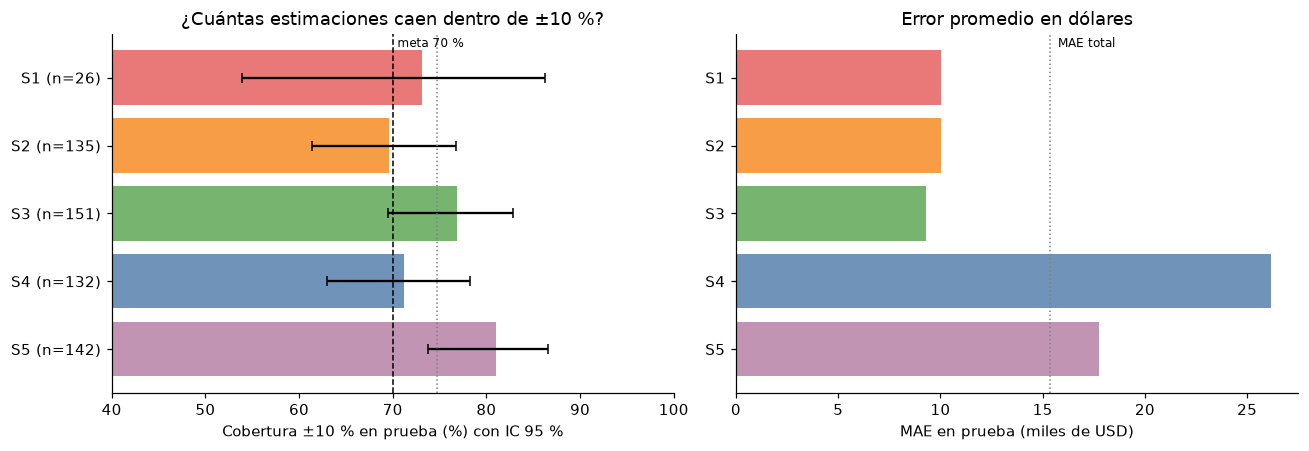

In [12]:
fig, ax = plt.subplots(1, 2, figsize=(12, 4.2))
y = np.arange(len(orden))[::-1]
cob = por_segmento.loc[orden]
err = np.vstack([cob["cobertura_10"] - cob["cobertura_IC95_inf"], cob["cobertura_IC95_sup"] - cob["cobertura_10"]]) * 100
ax[0].barh(y, cob["cobertura_10"] * 100, xerr=err, color=[colores[s] for s in orden], alpha=0.8, capsize=3)
ax[0].axvline(70, color="black", ls="--", lw=1); ax[0].text(70.5, y.max() + 0.45, "meta 70 %", fontsize=8)
ax[0].axvline(global_["cobertura_10"].iloc[0] * 100, color="gray", ls=":", lw=1)
ax[0].set_yticks(y); ax[0].set_yticklabels([f"{etiq_corta[s]} (n={int(cob.loc[s, 'n_prueba'])})" for s in orden])
ax[0].set_xlabel("Cobertura ±10 % en prueba (%) con IC 95 %"); ax[0].set_xlim(40, 100)
ax[0].set_title("¿Cuántas estimaciones caen dentro de ±10 %?")

ax[1].barh(y, cob["MAE_USD"] / 1000, color=[colores[s] for s in orden], alpha=0.8)
ax[1].axvline(global_["MAE_USD"].iloc[0] / 1000, color="gray", ls=":", lw=1)
ax[1].text(global_["MAE_USD"].iloc[0] / 1000 + 0.4, y.max() + 0.45, "MAE total", fontsize=8)
ax[1].set_yticks(y); ax[1].set_yticklabels([etiq_corta[s] for s in orden])
ax[1].set_xlabel("MAE en prueba (miles de USD)"); ax[1].set_title("Error promedio en dólares")
plt.tight_layout()
plt.savefig(IMAGES / "segmentos_error_modelo.png", bbox_inches="tight")
plt.show()

### Interpretación de las métricas en términos de los KPIs del README

**KPI 1 — Cobertura ±10 % (meta ≥ 70 %).** El total es 74,7 % (IC 95 %: 71,1–78,1 %), sobre la meta. Pero el promedio esconde diferencias entre segmentos:

| Segmento | n prueba | Cobertura | IC 95 % | Lectura |
|---|---:|---:|---|---|
| S5 Dos pisos amplias, recientes | 142 | 81,0 % | 73,7–86,6 % | Cumple; único segmento cuyo intervalo queda completo sobre 70 %. |
| S3 Un piso medio, años 60 | 151 | 76,8 % | 69,5–82,8 % | Cumple en la cifra puntual; el intervalo toca el 70 %. |
| S1 Dúplex y multifamiliares | 26 | 73,1 % | 53,9–86,3 % | **No concluyente:** solo 26 viviendas. |
| S4 Un piso reciente, mayor calidad | 132 | 71,2 % | 63,0–78,2 % | Cumple por poco; intervalo amplio. |
| S2 Antiguas y compactas | 135 | 69,6 % | 61,4–76,8 % | 0,4 puntos bajo la meta en la cifra puntual, pero **estadísticamente indistinguible de 70 %**. |

Ningún segmento puede declararse "bajo la meta" con certeza, y solo S5 puede declararse "sobre la meta". Con 26 a 151 viviendas por segmento la evidencia es más débil que a nivel global.

**KPI 2 — Mejora del MAE respecto de la mediana (meta ≥ 15 %).** Se cumple con holgura en todos los segmentos: entre 61,4 % (S3) y 79,0 % (S5), frente a 76,0 % global. S3 tiene la mejora más baja porque sus precios ya están cerca de la mediana, por lo que la referencia simple es allí menos mala.

**MAE en dólares.** El error absoluto crece con el valor de la vivienda: 9.297 USD en S3 contra 26.177 USD en S4, es decir 1,7 veces el MAE global (15.350 USD). En términos relativos las diferencias son mucho menores (error relativo mediano entre 4,8 % y 6,1 %). Un error de ±10 % de una vivienda de 290.000 USD son ±29.000 USD, una cifra que el negocio debe aceptar de forma explícita.

**Coherencia con la Parte 2.** El total (586 viviendas) reproduce exactamente las cifras de la Parte 2 (MAE 15.350 USD; cobertura 74,7 %), lo que confirma que la alineación entre segmentos y predicciones es correcta. Los segmentos aportan una lectura que el análisis por barrio y por cuartil de precio no daba por separado: S2 reúne las viviendas de menor precio (donde la Parte 2 halló la cobertura más baja, 63,3 % en Q1) y S4 incluye una parte importante de NridgHt (20 % del segmento), el barrio con mayor error absoluto entre los grandes.

## 7. Recomendaciones de negocio

Cada recomendación apunta a un resultado numérico de este notebook. Ninguna afirma ahorros, tiempos de venta o beneficios operacionales, porque no se midieron (README, secciones 4.3 y 7.2).

**R1. Usar el modelo como primera estimación en S3 y S5, con control de muestra.** Son los segmentos con mejor cobertura puntual (76,8 % y 81,0 %) y suman 53 % de las viviendas. En S5 el intervalo de confianza queda sobre la meta (73,7 %). *Límite:* son estimaciones de apoyo, no tasaciones.

**R2. Exigir revisión de un tasador en S2 (Antiguas y compactas).** Su cobertura es 69,6 % (IC 61,4–76,8 %), la más baja, y concentra el rango de precios bajos (65 % de sus viviendas ≤ 129.000 USD), donde la Parte 2 midió 63,3 % de cobertura. Una regla concreta: la estimación del modelo no se entrega sola, sino acompañada de la revisión de una muestra de estas viviendas hasta confirmar si la cobertura real supera 70 %.

**R3. En S4 (Un piso reciente, mayor calidad), comunicar la estimación como rango en USD y no como cifra única.** Su MAE es 26.177 USD, 1,7 veces el global, y su valor por operación es el más alto (mediana 230.174 USD). Una presentación como "precio estimado ± 26.000 USD" refleja el error observado.

**R4. No usar el modelo para dúplex y multifamiliares (S1) hasta reunir más datos.** Solo hay 118 viviendas en el conjunto y 26 en prueba (IC 53,9–86,3 %): los datos no permiten afirmar ni que funcione ni que falle. Derivar estos casos a valoración manual y, si se vuelven frecuentes, registrar más ejemplos para entrenar un modelo específico.

**R5. Informar los KPIs por segmento, no solo el total.** El 74,7 % global oculta un rango de 69,6 % a 81,0 % entre segmentos. Un tablero de seguimiento con cobertura y MAE por segmento detecta antes un deterioro. Los segmentos se asignan a viviendas nuevas con `kmeans.predict` sobre las componentes PCA.

### Limitaciones

- **Estructura débil:** silhouette de 0,118 con k = 5. Los segmentos son una partición útil, no grupos naturales; con otra semilla, otro método o otro k los bordes cambian (ARI K-Means–Ward = 0,595; estabilidad bootstrap = 0,867).
- **Muestras pequeñas por segmento:** entre 26 y 151 viviendas de prueba. Los intervalos de confianza son amplios y las diferencias entre S1–S4 en cobertura no son estadísticamente concluyentes.
- **El clustering usó las 2.930 viviendas, incluidas las de prueba** (sin el precio). No hay fuga del objetivo, pero la estructura de los grupos sí incorpora las características de las viviendas de prueba.
- **Sin validación operacional:** las recomendaciones R1–R5 se derivan de errores de predicción, no de un piloto con tasadores.
- **Alcance temporal y geográfico:** datos de una sola ciudad (Ames, Iowa) con ventas entre 2006 y 2010. El modelo no refleja la inflación ni el mercado actual y no debe aplicarse a precios actuales ni a otras ciudades sin revalidación.
- **Asociación, no causalidad:** que las viviendas recientes de calidad 7 cuesten más no prueba que mejorar la calidad suba el precio en esa cuantía.

### Revisión ética final (complementa el README, sección 7.3)

- **Diferencias de desempeño entre grupos:** la cobertura varía de 69,6 % (S2) a 81,0 % (S5). Las viviendas más baratas (S2) son las que reciben las estimaciones menos fiables; usar el modelo sin revisión podría perjudicar de forma sistemática a quien compre o venda ese tipo de propiedad. La recomendación R2 busca mitigarlo.
- **Segmentación estigmatizante:** los nombres usan solo características de la edificación. No se rotularon segmentos por barrio y no se atribuyen rasgos a los habitantes.
- **Uso responsable:** los segmentos no deben usarse para decidir sobre personas (créditos, seguros, acceso a vivienda).
- **Lo que no se hizo:** no hay auditoría formal de equidad. La ausencia de diferencias estadísticamente significativas no demuestra ausencia de sesgo.

### Trabajo futuro

1. Comprobar si agregar el segmento como variable mejora el modelo (con validación cruzada sobre entrenamiento).
2. Modelo específico o más datos para S1 (dúplex).
3. Validación cruzada anidada y grilla más amplia del boosting (README, sección 12.6).
4. Piloto con tasadores para medir tiempo y calidad reales.

In [13]:
# Verificación final de las salidas de la Parte 3
c = load_data("clusters.csv")
assert c.shape == (2930, 3)
assert c["cluster"].nunique() == K_FINAL
assert (c["indice_original"].to_numpy() == ref.to_numpy()).all()
for archivo in ["clustering_pca_varianza.png", "clustering_k.png", "segmentos_pca.png",
                "segmentos_precio.png", "segmentos_perfil.png", "segmentos_error_modelo.png"]:
    assert (IMAGES / archivo).is_file(), archivo
assert (MODELS / "results_segments.csv").is_file()

# Cifras citadas en el texto: si algo cambia al re-ejecutar (otra versión de scikit-learn), este bloque lo avisa
esperado = {"S1": 118, "S2": 692, "S3": 866, "S4": 580, "S5": 674}
reales = datos.groupby(datos["segmento"].str[:2]).size().to_dict()
print("Tamaños de segmento:", reales)
assert reales == esperado, "Los tamaños de segmento cambiaron: revisar las cifras del texto del notebook y del README"
print("Verificación completada.")

Tamaños de segmento: {'S1': 118, 'S2': 692, 'S3': 866, 'S4': 580, 'S5': 674}
Verificación completada.
